---
title: "Lecture 16: Central Limit Theorem, Strong Law of Large Numbers, Chernoff's Bound"
author: "Jamie Haddock"
format:
    revealjs:
        output-file: Lecture16_slides
        slide-number: true
        preview-links: auto
        logo: figs/hmc.png
        css: input/slides.css
        incremental: true
        smaller: true
        code-fold: true
        embed-resources: true
        html-math-method: katex
        slide-level: 3
    html:
        code-fold: true
        embed-resources: true
        output-file: Lecture16
        code-links:
          - text: "Open in Colab"
            href: "https://colab.research.google.com/github/jamiehadd/Math-151-Probability/blob/main/16_clt-slln-chernoff-bound.ipynb"
            icon: "laptop"
    pdf:
        documentclass: article
        toc: true
        number-sections: true
        output-file: Lecture16
        geometry:
          - top=1in
          - left=1in
          - bottom=1in
          - right=1in
format-links: false
jupyter: python3
colab:
  gh-user: "jamiehadd"
  gh-repo: "Math-151-Probability"
filters:
  - input/remove-pause.lua
  - colab
execute:
  echo: true
  eval: true
---

# Recap

- **WLLN:** $\bar{X}_n \to \mu$ in probability, since $\operatorname{Var}(\bar{X}_n) = \sigma^2/n \to 0$.
- What about $Z_n$?

*[Summary diagram to be added.]*

# Chernoff's Bound

**Motivation.** Chebyshev only gives $1/n$ decay for $P(|\bar{X}_n - \mu| \ge \varepsilon)$, but the true probability decays exponentially.

## Chernoff's Bound

::: {.callout-note title="Theorem (Chernoff)"}
Let $M(s) = E[e^{sX}]$. For any $a$ and $s > 0$,
$$P(X \ge a) \le e^{-sa} M(s).$$
Hence $P(X \ge a) \le \min_{s > 0}\, e^{-sa} M(s)$.
:::

. . .

**Proof.** The event $\{X \ge a\}$ equals $\{e^{sX} \ge e^{sa}\}$. Apply Markov to the nonnegative RV $e^{sX}$:
$$P(e^{sX} \ge e^{sa}) \le \frac{E[e^{sX}]}{e^{sa}} = e^{-sa} M(s). \qquad \square$$

### Application to $\bar{X}_n$ where $X_i \sim \text{Bernoulli}(p)$

For $a > p$, with $M(s) = 1 - p + pe^s$:
$$P(\bar{X}_n \ge a) = P(S_n \ge na) \le \left[e^{-sa} M(s)\right]^n.$$

. . .

Optimizing over $s$:
$$P(\bar{X}_n \ge a) \le e^{-n I(a)}, \qquad I(a) = a \ln\frac{a}{p} + (1-a)\ln\frac{1-a}{1-p}.$$

In particular, $P(\bar{X}_n \ge p + \varepsilon) \le e^{-2n\varepsilon^2}$.

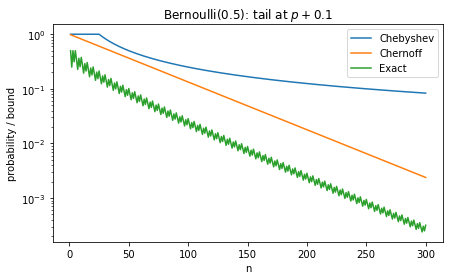

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import binom, norm

p, eps = 0.5, 0.1
a = p + eps
ns = np.arange(1, 301)

exact = np.array([binom.sf(np.ceil(n * a - 1e-9) - 1, n, p) for n in ns])
cheb = np.minimum(1, p * (1 - p) / (ns * eps**2))
I = a * np.log(a / p) + (1 - a) * np.log((1 - a) / (1 - p))
chernoff = np.exp(-ns * I)

plt.figure(figsize=(7, 4))
plt.semilogy(ns, cheb, label="Chebyshev")
plt.semilogy(ns, chernoff, label="Chernoff")
plt.semilogy(ns, exact, label="Exact")
plt.xlabel("n")
plt.ylabel("probability / bound")
plt.title(r"Bernoulli(0.5): tail at $p + 0.1$")
plt.legend()
plt.show()

## Summary

- Chebyshev: polynomial decay. Chernoff: exponential decay (needs the MGF).

*[Update summary diagram.]*

# Central Limit Theorem

What is the distribution of $Z_n = \dfrac{S_n - n\mu}{\sigma\sqrt{n}}$?

Recall: $E[Z_n] = 0$ and $\operatorname{Var}(Z_n) = 1$.

## Central Limit Theorem

::: {.callout-note title="Theorem (CLT)"}
Let $X_1, X_2, \dots$ be iid with mean $\mu$ and variance $\sigma^2$. Then for every $z$,
$$P(Z_n \le z) \to \Phi(z) \quad \text{as } n \to \infty,$$
where $\Phi$ is the standard normal CDF.
:::

- Random effects are often the sum of a large number of small random factors (e.g., noise).
- We don't need tedious PMFs/PDFs in this case, just the standard normal CDF $\Phi$!

## Central Limit Theorem

**MGF proof.** Assume the MGF $M$ of $X$ exists near $0$; WLOG $\mu = 0$, $\sigma = 1$.

1. By independence, the MGF of $Z_n$ is $\left[M(s/\sqrt{n})\right]^n$.

. . .

2. Since $E[X] = 0$ and $E[X^2] = 1$: $M(u) = 1 + \dfrac{u^2}{2} + o(u^2)$.

. . .

3. So $\left[M(s/\sqrt{n})\right]^n = \left[1 + \dfrac{s^2}{2n} + o\!\left(\dfrac{1}{n}\right)\right]^n \to e^{s^2/2}$, the MGF of $N(0,1)$.

. . .

4. MGF convergence implies convergence in distribution. $\square$

## Convergence in Distribution

::: {.callout-note title="Definition"}
$Y_n \to Y$ **in distribution** if $F_{Y_n}(y) \to F_Y(y)$ at every $y$ where $F_Y$ is continuous.
:::

- The CLT says $Z_n \to N(0,1)$ in distribution.

. . .

- Convergence in probability $\Rightarrow$ convergence in distribution.
- The converse is false in general (e.g., $Y_n = -X$ with $X \sim N(0,1)$ has the same distribution as $X$ but does not converge to it in probability), but true when the limit is a constant.

## Normal Approximation by CLT

**Process.** To approximate $P(S_n \le c)$:

1. Compute $\mu$, $\sigma^2$, and $n$.
2. Standardize: $P(S_n \le c) = P\!\left(Z_n \le \dfrac{c - n\mu}{\sigma\sqrt{n}}\right)$.
3. Approximate: $\approx \Phi\!\left(\dfrac{c - n\mu}{\sigma\sqrt{n}}\right)$.

### Example: polling

How many people must we poll so the estimate is within $\varepsilon = 0.01$ of $p$ with probability at least $0.95$? (Worst case $\sigma = 1/2$.)

$$P(|\bar{X}_n - p| \ge \varepsilon) = P\!\left(|Z_n| \ge \frac{\varepsilon\sqrt{n}}{\sigma}\right) \approx 2\left(1 - \Phi\!\left(\frac{\varepsilon\sqrt{n}}{\sigma}\right)\right) \le 0.05$$

. . .

$$\iff \frac{\varepsilon\sqrt{n}}{\sigma} \ge 1.96 \iff n \ge \left(\frac{1.96 \cdot 0.5}{0.01}\right)^2 = 9604.$$

. . .

| Method | $n \ge$ |
|---|---|
| Chebyshev | 50,000 |
| Chernoff | 18,445 |
| CLT (approximation) | 9,604 |

### De Moivre–Laplace Approximation to Binomial

If $S_n \sim \text{Binomial}(n, p)$, then $\mu = np$, $\sigma^2 = np(1-p)$, and
$$P(S_n \le k) \approx \Phi\!\left(\frac{k + \tfrac{1}{2} - np}{\sqrt{np(1-p)}}\right).$$

(The $\tfrac{1}{2}$ is the continuity correction.)

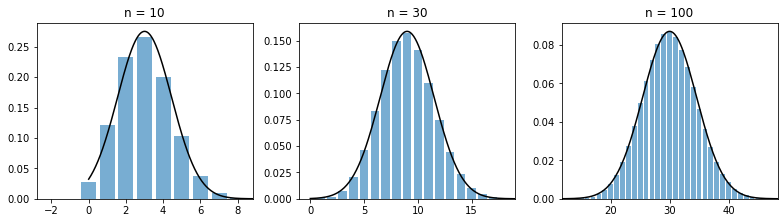

In [2]:
p = 0.3
fig, axes = plt.subplots(1, 3, figsize=(11, 3.2))
for ax, n in zip(axes, [10, 30, 100]):
    k = np.arange(0, n + 1)
    mu, sd = n * p, np.sqrt(n * p * (1 - p))
    ax.bar(k, binom.pmf(k, n, p), alpha=0.6)
    x = np.linspace(0, n, 400)
    ax.plot(x, norm.pdf(x, mu, sd), "k")
    ax.set_xlim(mu - 4 * sd, mu + 4 * sd)
    ax.set_title(f"n = {n}")
plt.tight_layout()
plt.show()

## Summary

- CLT: $Z_n \to N(0,1)$ in distribution.

*[Update summary diagram.]*

# Strong Law of Large Numbers

## SLLN

::: {.callout-note title="Theorem (SLLN)"}
Let $X_1, X_2, \dots$ be iid with mean $\mu$. Then $\bar{X}_n \to \mu$ **almost surely**:
$$P\!\left(\lim_{n \to \infty} \bar{X}_n = \mu\right) = 1.$$
:::

## SLLN

**Proof under fourth moments.** Assume $E[X^4] < \infty$; WLOG $\mu = 0$.

1. Expand $S_n^4$: terms with a lone $X_i$ vanish, so
$$E[S_n^4] = nE[X^4] + 3n(n-1)\sigma^4 \le Cn^2, \qquad C = E[X^4] + 3\sigma^4.$$

. . .

2. Hence $E[\bar{X}_n^4] \le C/n^2$, and
$$E\!\left[\sum_{n=1}^\infty \bar{X}_n^4\right] = \sum_{n=1}^\infty E[\bar{X}_n^4] \le \sum_{n=1}^\infty \frac{C}{n^2} < \infty.$$

. . .

3. A nonnegative RV with finite expectation is finite almost surely, so $\sum_n \bar{X}_n^4 < \infty$ almost surely.

. . .

4. Terms of a convergent series go to $0$, so $\bar{X}_n \to 0$ almost surely. $\square$

## SLLN

**Interpretation.** Along (almost) every infinite sequence of samples, the running average settles down to $\mu$.

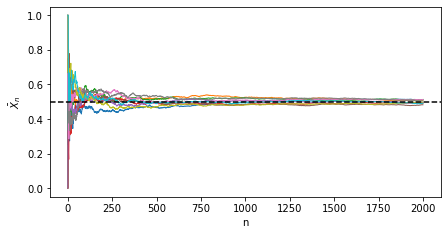

In [3]:
rng = np.random.default_rng(151)
n, paths = 2000, 10
X = rng.binomial(1, 0.5, size=(paths, n))
means = np.cumsum(X, axis=1) / np.arange(1, n + 1)

plt.figure(figsize=(7, 3.5))
plt.plot(means.T, lw=1)
plt.axhline(0.5, color="k", ls="--")
plt.xlabel("n")
plt.ylabel(r"$\bar{X}_n$")
plt.show()

## SLLN

**Relationship between SLLN and WLLN.**

- SLLN $\Rightarrow$ WLLN, since almost sure convergence implies convergence in probability.
- WLLN controls each $\bar{X}_n$ separately; SLLN controls the whole sequence at once.

## Almost Sure Convergence

::: {.callout-note title="Definition"}
$Y_n \to Y$ **almost surely** if $P\!\left(\lim_{n \to \infty} Y_n = Y\right) = 1$.
:::

. . .

**Application to the SLLN, and comparison with the other modes:**
$$\text{almost sure} \;\Longrightarrow\; \text{in probability} \;\Longrightarrow\; \text{in distribution}.$$

- SLLN: $\bar{X}_n \to \mu$ almost surely. WLLN: $\bar{X}_n \to \mu$ in probability. CLT: $Z_n \to N(0,1)$ in distribution.
- The converses are false in general.

### Example: min of uniform RVs

Let $U_1, U_2, \dots$ be iid $\text{Uniform}(0,1)$ and $Y_n = \min(U_1, \dots, U_n)$.

- $Y_n$ is nonincreasing and $\ge 0$, so $Y_n \to Y_\infty$ for every outcome.
- $Y_\infty \le Y_n$ for all $n$, so for $0 < \varepsilon < 1$,
$$P(Y_\infty \ge \varepsilon) \le P(Y_n \ge \varepsilon) = (1 - \varepsilon)^n \to 0.$$
- So $Y_\infty = 0$ almost surely: $Y_n \to 0$ almost surely.

### Example: something that converges to 0 in probability, but not almost surely

Let $Y_n \sim \text{Bernoulli}(1/n)$ be independent.

- **In probability:** $P(|Y_n| \ge \varepsilon) = 1/n \to 0$ for $0 < \varepsilon \le 1$.

. . .

- **Not almost surely:** for any $m \ge 2$,
$$P(Y_n = 0 \text{ for all } n \ge m) = \prod_{n=m}^\infty \left(1 - \frac{1}{n}\right) = \lim_{N \to \infty} \frac{m-1}{N} = 0.$$
So almost surely $Y_n = 1$ infinitely often, and $Y_n \not\to 0$.

## Summary

- SLLN: $\bar{X}_n \to \mu$ almost surely.

*[Update summary diagram.]*